# 04 · Support operations analytics

> **All data in this notebook are synthetic** (fictional Indian retail brokerage, 10,000 users, Nov 2025 - Oct 2026, INR, snapshot 2026-10-31). No real company data are used.

Resolution time and CSAT exist only for **resolved** tickets. Unresolved = Open + Escalated.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from fintech_analytics import config as C, loading, cleaning, eda, funnel, campaign, cohort, segmentation, support, kpi_report
%matplotlib inline
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
d = loading.load_all(); users, act, tix, camp = d['users'], d['activity'], d['tickets'], d['campaigns']
print(f'users={len(users):,}  monthly rows={len(act):,}  tickets={len(tix):,}  campaigns={len(camp)}  (ALL DATA SYNTHETIC)')

users=10,000  monthly rows=64,645  tickets=7,614  campaigns=10  (ALL DATA SYNTHETIC)


In [2]:
pd.Series(support.ticket_kpis(tix, len(users))).round(2).to_frame('value')

,value
tickets,7614.00
tickets_per_1000_users,761.40
users_with_ticket_pct,52.44
resolved_pct,81.99
open,892.00
escalated,479.00
unresolved,1371.00
median_resolution_h,9.40
mean_resolution_h,10.89
p90_resolution_h,20.40


## Categories

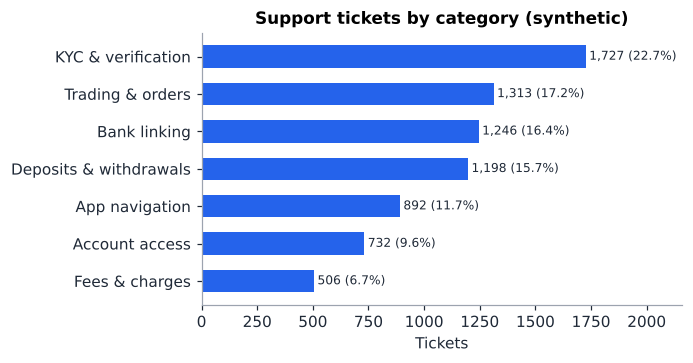

,category,tickets,users_affected,high_priority,escalated,unresolved,median_resolution_h,mean_resolution_h,avg_csat,share_pct
0,KYC & verification,1727,1579,276,107,316,9.50,10.93,3.77,22.68
1,Trading & orders,1313,1215,185,85,226,9.30,10.69,3.85,17.24
2,Bank linking,1246,1167,195,94,242,9.60,10.80,3.81,16.36
3,Deposits & withdrawals,1198,1128,172,72,218,9.55,11.03,3.83,15.73
4,App navigation,892,849,153,47,165,9.70,11.22,3.86,11.72
5,Account access,732,699,113,44,118,9.10,10.49,3.89,9.61
6,Fees & charges,506,494,77,30,86,9.05,11.15,3.83,6.65


In [3]:
support.plot_category(tix); plt.tight_layout(); plt.show()
support.category_table(tix)

## Backlog ageing (unresolved tickets)

In [4]:
support.backlog_table(tix)

priority,backlog_age_bucket,High,Low,Medium,total
0,0-30d,68,146,185,399
1,31-90d,58,145,206,409
2,91-180d,67,112,176,355
3,>180d,28,74,106,208


## Monthly trend

In [5]:
support.monthly_ticket_trend(tix)

,created_month,tickets,median_resolution_h,avg_csat
0,2025-11,30,10.50,3.41
1,2025-12,101,11.90,3.80
2,2026-01,164,10.30,4.06
3,2026-02,208,8.85,3.85
4,2026-03,298,9.40,3.90
5,2026-04,393,9.55,3.75
6,2026-05,519,9.60,3.83
7,2026-06,661,9.40,3.83
8,2026-07,809,8.70,3.80
9,2026-08,1026,9.30,3.83


## Repeat contactors (3+ tickets)

In [6]:
rc = support.repeat_contactors(tix); print(len(rc), 'users with 3+ tickets'); rc.groupby('tickets').agg(users=('user_id','size'), avg_csat=('avg_csat','mean')).round(2)

450 users with 3+ tickets


,users,avg_csat
tickets,,
3,336,3.79
4,100,3.75
5,12,3.95
6,1,4.00
7,1,3.67


## Support exposure vs dormancy (descriptive only)
This does not adjust for cohort age or channel mix. Phase 3 used a cohort-adjusted test for the formal claim; here it is only a screening view.

In [7]:
x = users[users.dormant_3m_monthly.notna()].assign(support_status=lambda d: np.select([d.ticket_count==0, d.unresolved_ticket_count>0], ['0 tickets','Has unresolved ticket'], 'Tickets all resolved'))
x.groupby('support_status').agg(users=('user_id','size'), dormant_3m_pct=('dormant_3m_monthly', lambda s: 100*s.mean())).round(1)

,users,dormant_3m_pct
support_status,,
0 tickets,3473,20.8
Has unresolved ticket,984,23.8
Tickets all resolved,2977,22.7
